## Track A: live optical density (OD) from the Pioreactor

Objectives 2 and 3: find the running experiment, read its OD, and show a live timestamped stream.

The API sits behind a Cloudflare tunnel that can go down. So every reading we fetch is **recorded** to
`robotics/evidence/reactor/od_log.csv`, and when the API is unreachable the same functions **replay** that log.
The notebook therefore runs anywhere, with or without the reactor.

Contract with the arm track (`arm.py`): `latest_od(EXPERIMENT) -> (iso_timestamp, od) | None`.

In [1]:
import csv
import json
import os
import time
import urllib.error
import urllib.parse
import urllib.request
from datetime import datetime, timezone
from pathlib import Path

# Organisers' tunnel by default. For our own reactor on the same network, set PIOREACTOR_API before running,
# e.g. PIOREACTOR_API=http://<hostname>.local/api, or assign od.API in the notebook.
API = os.environ.get("PIOREACTOR_API", "https://api.environnets.com/api").rstrip("/")
TIMEOUT_S = 8
MODE = "auto"        # "auto": live, falling back to replay on failure | "live": never replay | "replay": never call the API

try:
    HERE = Path(__file__).resolve().parent
except NameError:    # running as a notebook cell
    HERE = Path.cwd() / "robotics" if (Path.cwd() / "robotics").is_dir() else Path.cwd()
LOG = HERE / "evidence" / "reactor" / "od_log.csv"
LOG_FIELDS = ["fetched_at", "experiment", "series", "timestamp", "od"]


class ApiDown(Exception):
    """The Pioreactor API could not be reached or returned something unusable."""


def _get(path):
    """GET API + path and parse JSON. Raises ApiDown on any network, HTTP or JSON failure."""
    return _get_url(API + path)


def _get_url(url):
    req = urllib.request.Request(url, headers={"Accept": "application/json",
                                               "User-Agent": "jsnn-hackathon-robotics"})
    try:
        with urllib.request.urlopen(req, timeout=TIMEOUT_S) as resp:
            return json.loads(resp.read().decode())
    except (urllib.error.URLError, TimeoutError, json.JSONDecodeError, ValueError) as err:
        raise ApiDown(f"{url}: {err}") from err

### Objective 2: find the experiment and retrieve its OD

`/experiments/latest` gives the running experiment. `/experiments/{exp}/time_series/od_readings?lookback=2`
gives the last 2 hours of raw OD for every unit and channel, as series labels plus lists of points.
The exact keys are unverified until the API is up, so the parser accepts the common spellings
(`series`/`data`, `x`/`timestamp`, `y`/`value`) and raises a clear error otherwise.

In [2]:
def _read_log():
    if not LOG.exists():
        return []
    with LOG.open(newline="") as f:
        return list(csv.DictReader(f))


def get_latest_experiment():
    """Name of the running experiment; if the API is down, the experiment in the log; else None."""
    if MODE != "replay":
        try:
            body = _get("/experiments/latest")
            name = body.get("experiment") if isinstance(body, dict) else None
            if name:
                return name
            raise ApiDown(f"/experiments/latest: no 'experiment' key in {str(body)[:200]}")
        except ApiDown:
            if MODE == "live":
                raise
    rows = _read_log()
    return rows[-1]["experiment"] if rows else None


def _parse_series(body):
    """Turn the time_series response into {series_label: [(iso_timestamp, od), ...]} sorted by time."""
    if not isinstance(body, dict):
        raise ApiDown(f"od_readings: expected an object, got {type(body).__name__}")
    labels = body.get("series") or body.get("labels") or []
    data = body.get("data") or []
    if len(labels) != len(data):
        raise ApiDown(f"od_readings: {len(labels)} series labels but {len(data)} data lists; keys={list(body)}")
    out = {}
    for label, points in zip(labels, data):
        pts = []
        for p in points:
            ts = p.get("x", p.get("timestamp")) if isinstance(p, dict) else p[0]
            val = p.get("y", p.get("value")) if isinstance(p, dict) else p[1]
            if ts is None or val is None:
                continue
            pts.append((str(ts), float(val)))
        out[str(label)] = sorted(pts)
    return out


def get_od_series(experiment, lookback_hours=2):
    """All OD series for an experiment from the live API, recorded to the log. Raises ApiDown."""
    path = f"/experiments/{urllib.parse.quote(experiment, safe='')}/time_series/od_readings?lookback={lookback_hours}"
    series = _parse_series(_get(path))
    _record(experiment, series)
    return series

### Record and replay

Each new point is appended once to `od_log.csv` (deduplicated on series + timestamp). In replay mode,
successive calls to `latest_od` step through the logged points in time order, as if they were arriving live,
and wrap around at the end so a replayed demo can be repeated exactly.

In [3]:
def _record(experiment, series):
    seen = {(r["series"], r["timestamp"]) for r in _read_log()}
    new = [(label, ts, od) for label, pts in series.items() for ts, od in pts if (label, ts) not in seen]
    if not new:
        return 0
    LOG.parent.mkdir(parents=True, exist_ok=True)
    write_header = not LOG.exists()
    now = datetime.now(timezone.utc).isoformat(timespec="seconds")
    with LOG.open("a", newline="") as f:
        w = csv.writer(f)
        if write_header:
            w.writerow(LOG_FIELDS)
        for label, ts, od in sorted(new, key=lambda r: r[1]):
            w.writerow([now, experiment, label, ts, od])
    return len(new)


_replay_pos = 0


def reset_replay():
    """Start replay from the first logged reading again."""
    global _replay_pos
    _replay_pos = 0


def _replay_next(experiment, series_label=None):
    """Next logged point for this experiment (and series), cycling through the log. None if the log is empty."""
    global _replay_pos
    rows = [r for r in _read_log()
            if (experiment is None or r["experiment"] == experiment)
            and (series_label is None or r["series"] == series_label)]
    if not rows:
        return None
    rows.sort(key=lambda r: (r["timestamp"], r["series"]))
    row = rows[_replay_pos % len(rows)]
    _replay_pos += 1
    return row["timestamp"], float(row["od"])

### The contract: `EXPERIMENT` and `latest_od`

One reading: the newest point of **one** series. Mixing units or channels would make the value jump between
vessels and trigger the arm on noise, so a single series is used: `series_label` if given, else `OD_SERIES`,
else the first series alphabetically (e.g. `unit1-2`). The chosen label is kept in `SERIES_USED`.

In [4]:
OD_SERIES = None     # set to a label such as "unit1-2" to pin the vessel/channel
SOURCE = None        # "live" or "replay": where the last latest_od() reading came from
SERIES_USED = None


def _when(iso):
    return datetime.fromisoformat(iso.replace("Z", "+00:00"))


def leader_now():
    """The leader's own clock (ISO string) from /unit_api/health, or None if unavailable.

    A Pioreactor without internet can boot with a wrong clock (ours read 2025-10-01), so new readings can be
    dated *before* older ones. "Newest" therefore means the latest point at or before the leader's clock,
    not the last point by timestamp. This stays correct whether the clock is wrong or right.
    """
    try:
        body = _get_url(API.rsplit("/api", 1)[0] + "/unit_api/health")
        return body.get("utc_time") if isinstance(body, dict) else None
    except ApiDown:
        return None


def _newest(points, now_iso):
    if not points:
        return None
    if now_iso:
        now = _when(now_iso)
        past = [p for p in points if _when(p[0]) <= now]
        if past:
            return max(past, key=lambda p: _when(p[0]))
    return max(points, key=lambda p: _when(p[0]))


def latest_od(experiment, series_label=None):
    """(ISO timestamp, OD) of the newest reading, or None if there is no live data and nothing to replay."""
    global SOURCE, SERIES_USED
    wanted = series_label or OD_SERIES
    if MODE != "replay" and experiment:
        try:
            series = get_od_series(experiment)
            label = wanted or (min(series) if series else None)
            points = series.get(label, []) if label else []
            if points:
                SOURCE, SERIES_USED = "live", label
                return _newest(points, leader_now())
        except ApiDown:
            if MODE == "live":
                raise
    if MODE == "live":
        return None
    if wanted is None:
        labels = sorted({r["series"] for r in _read_log() if experiment is None or r["experiment"] == experiment})
        wanted = labels[0] if labels else None
    SOURCE, SERIES_USED = "replay", wanted
    return _replay_next(experiment, wanted)


EXPERIMENT = get_latest_experiment()   # None when the API is down and nothing has been logged yet
print(f"EXPERIMENT = {EXPERIMENT!r}  (mode {MODE}, log {'has data' if LOG.exists() else 'empty'})")

EXPERIMENT = 'bioreactor_robot'  (mode auto, log has data)


### Objective 3: a live, timestamped OD stream

Polls `latest_od` every `every` seconds for `seconds` seconds, prints a table row per new reading and redraws
a plot. Repeated readings (the reactor samples less often than we poll) are printed once.

In [5]:
def stream_od(seconds=60, every=5, experiment=None, series_label=None, plot=True):
    """Stream OD readings and return them as a list of (timestamp, od, source)."""
    experiment = experiment or EXPERIMENT or get_latest_experiment()
    header = (f"experiment: {experiment!r}   mode: {MODE}   log: {LOG}\n"
              f"{'polled at (UTC)':<27}{'reading timestamp':<34}{'OD':>10}  source")
    print(header)
    rows, readings, last_ts, end = [], [], None, time.time() + seconds
    while True:
        reading = latest_od(experiment, series_label)
        polled = datetime.now(timezone.utc).isoformat(timespec="seconds")
        if reading is None:
            print(f"{polled:<27}no data (API down and nothing logged)")
        elif reading[0] != last_ts:
            last_ts = reading[0]
            readings.append((*reading, SOURCE))
            rows.append(f"{polled:<27}{reading[0]:<34}{reading[1]:>10.4f}  {SOURCE}")
            if not (plot and _draw(header, rows, readings, experiment)):
                print(rows[-1])
        if time.time() + every > end:
            break
        time.sleep(every)
    return readings


def _draw(header, rows, readings, experiment):
    """In a notebook, redraw the whole table plus a plot in place. Returns False outside a notebook."""
    try:
        get_ipython  # noqa: F821
        import matplotlib.pyplot as plt
        from IPython.display import clear_output, display
    except (NameError, ImportError):
        return False
    clear_output(wait=True)
    print(header)
    print("\n".join(rows))
    fig, ax = plt.subplots(figsize=(8, 3))
    ax.plot(range(len(readings)), [r[1] for r in readings], "o-")
    ax.set(xlabel="reading #", ylabel="OD", title=f"Live OD: {experiment} ({readings[-1][2]})")
    ax.grid(alpha=0.3)
    display(fig)
    plt.close(fig)
    return True

**Live stream (objective 3).** 30 seconds of readings, polled every 5 s. Live when the reactor is up,
otherwise a replay of the recorded log. Runs in the notebook and as a script, not when imported.

experiment: 'bioreactor_robot'   mode: auto   log: /Users/alexwilliams/Developer/hackathon/jsnn-hackathon/robotics/evidence/reactor/od_log.csv
polled at (UTC)            reading timestamp                         OD  source
2026-11-07T20:00:13+00:00  2025-10-01T00:31:31.152Z              0.0048  live
2026-11-07T20:00:19+00:00  2025-10-01T00:31:36.152Z              0.0048  live
2026-11-07T20:00:24+00:00  2025-10-01T00:31:41.153Z              0.0048  live
2026-11-07T20:00:29+00:00  2025-10-01T00:31:46.152Z              0.0048  live
2026-11-07T20:00:35+00:00  2025-10-01T00:31:51.152Z              0.0048  live
2026-11-07T20:00:40+00:00  2025-10-01T00:31:56.152Z              0.0048  live


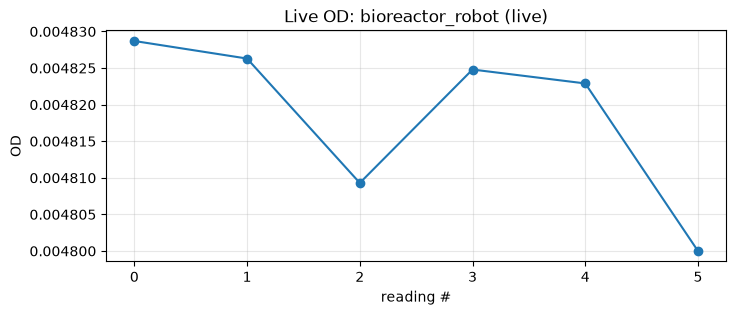

6 readings, series 'oliveirapioreactor01-2', source 'live'


In [6]:
if __name__ == "__main__":
    od_stream = stream_od(seconds=30, every=5)
    print(f"{len(od_stream)} readings, series {SERIES_USED!r}, source {SOURCE!r}")

## Part B: the myCobot 320 arm responds to optical density

**Objectives 4 and 5.** Connect to the arm, run a predefined test movement, then make the arm move when the
live optical density (OD) of the culture crosses a threshold.

**Runs anywhere.** If no arm is connected (in Colab, or on a judge's laptop) the notebook switches to
**dry-run mode**: it prints every command it would send and draws the arm's pose, so every step can still be
checked. On the laptop that is plugged into the arm, the same cells drive the real robot.

In [7]:
import importlib.util, subprocess, sys, os, glob, time, math
from datetime import datetime, timezone
from pathlib import Path

if importlib.util.find_spec("pymycobot") is None:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "pymycobot"], check=True)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROBOTICS_DIR = Path(".") if Path("PLAN.md").exists() else Path("robotics") if Path("robotics/PLAN.md").exists() else Path(".")
EVIDENCE = ROBOTICS_DIR / "evidence" / "arm"
EVIDENCE.mkdir(parents=True, exist_ok=True)

# Where the arm is. Leave as None to auto-detect; set ARM_PORT (USB, "M5" version) or ARM_IP (WiFi, "Pi" version).
ARM_PORT = os.environ.get("ARM_PORT")          # e.g. "/dev/tty.usbserial-0001" (Mac) or "COM3" (Windows)
ARM_IP = os.environ.get("ARM_IP")              # e.g. "192.168.1.42": on the arm's Pi run Server_320.py first
# Server_320.py (official, Elephant Robotics): https://raw.githubusercontent.com/elephantrobotics/pymycobot/main/demo/Server_320.py
# It listens on the Pi's WiFi address, port 9000. Or run this notebook ON the arm's Pi: it then uses /dev/ttyAMA0.
SPEED = 30                                     # percent of max speed: slow and safe

### Connect: real arm if we can find one, otherwise dry-run
The myCobot 320 comes in two versions. The **M5** version plugs into the laptop by USB (a serial port).
The **Pi** version has its own small computer and is reached over the network (port 9000).
We try both, and fall back to a stand-in "dry-run" arm with the same commands.

In [8]:
class DryRunArm:
    """Same commands as the real arm; records poses instead of moving motors."""
    name = "dry-run (no arm connected)"

    def __init__(self):
        self.angles = [0.0] * 6
        self.history = []

    def power_on(self):
        print("[dry-run] power_on")

    def send_angles(self, angles, speed, _async=False):
        print(f"[dry-run] send_angles({[round(a, 1) for a in angles]}, speed={speed})")
        self.angles = list(map(float, angles))
        self.history.append(list(self.angles))

    def get_angles(self):
        return list(self.angles)

    def is_moving(self):
        return 0

    def release_all_servos(self):
        print("[dry-run] release_all_servos")


def candidate_ports():
    pats = ["/dev/tty.usbserial*", "/dev/tty.SLAB_USBtoUART*", "/dev/tty.wchusbserial*",
            "/dev/cu.usbserial*", "/dev/ttyUSB*", "/dev/ttyACM*"]
    return sorted({p for pat in pats for p in glob.glob(pat)})


def connect_arm():
    from pymycobot import MyCobot320, MyCobot320Socket
    tries = []
    # Running ON the arm's own Raspberry Pi (myCobot 320 Pi): the motors are on /dev/ttyAMA0 at 115200 baud.
    if not ARM_PORT and not ARM_IP and os.path.exists("/dev/ttyAMA0"):
        for baud in (115200, 1000000):
            try:
                arm = MyCobot320("/dev/ttyAMA0", baud)
                arm.power_on()
                time.sleep(0.5)
                if arm.get_angles():
                    arm.name = f"myCobot 320 Pi (on-board, /dev/ttyAMA0 @ {baud})"
                    return arm
                tries.append(f"/dev/ttyAMA0 @ {baud}: no answer")
            except Exception as e:
                tries.append(f"/dev/ttyAMA0 @ {baud}: {e}")
    for port in ([ARM_PORT] if ARM_PORT else candidate_ports()):
        try:
            arm = MyCobot320(port, 115200)
            arm.power_on()
            time.sleep(0.5)
            if arm.get_angles():                       # the arm answered
                arm.name = f"myCobot 320 M5 on {port}"
                return arm
            tries.append(f"{port}: no answer")
        except Exception as e:
            tries.append(f"{port}: {e}")
    if ARM_IP:
        try:
            arm = MyCobot320Socket(ARM_IP, 9000)
            arm.power_on()
            time.sleep(0.5)
            if arm.get_angles():
                arm.name = f"myCobot 320 Pi at {ARM_IP}"
                return arm
            tries.append(f"{ARM_IP}: no answer")
        except Exception as e:
            tries.append(f"{ARM_IP}: {e}")
    for t in tries:
        print("  tried", t)
    return DryRunArm()


arm = connect_arm()
print("Arm:", arm.name)

Arm: dry-run (no arm connected)


### Objective 4: a predefined test movement
Small joint moves at low speed, waiting for each move to finish before the next. **Every move is relative to
the pose the arm is already in** (no big swing to an absolute "zero" pose): turn the base left → right,
lift and lower the wrist, then return to the starting pose. Every pose is checked by reading the angles back.

starting pose: [0.0, 0.0, 0.0, 0.0, 0.0, 0.0]
[dry-run] send_angles([0.0, 0.0, 0.0, 0.0, 0.0, 0.0], speed=30)


[dry-run] send_angles([20.0, 0.0, 0.0, 0.0, 0.0, 0.0], speed=30)


[dry-run] send_angles([-20.0, 0.0, 0.0, 0.0, 0.0, 0.0], speed=30)


[dry-run] send_angles([0.0, 0.0, 0.0, 20.0, 0.0, 0.0], speed=30)


[dry-run] send_angles([0.0, 0.0, 0.0, -20.0, 0.0, 0.0], speed=30)


[dry-run] send_angles([0.0, 0.0, 0.0, 0.0, 0.0, 0.0], speed=30)


,step,target,reached
0,start,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0]","[0.0, 0.0, 0.0, 0.0, 0.0, 0.0]"
1,base left,"[20.0, 0.0, 0.0, 0.0, 0.0, 0.0]","[20.0, 0.0, 0.0, 0.0, 0.0, 0.0]"
2,base right,"[-20.0, 0.0, 0.0, 0.0, 0.0, 0.0]","[-20.0, 0.0, 0.0, 0.0, 0.0, 0.0]"
3,wrist up,"[0.0, 0.0, 0.0, 20.0, 0.0, 0.0]","[0.0, 0.0, 0.0, 20.0, 0.0, 0.0]"
4,wrist down,"[0.0, 0.0, 0.0, -20.0, 0.0, 0.0]","[0.0, 0.0, 0.0, -20.0, 0.0, 0.0]"
5,start,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0]","[0.0, 0.0, 0.0, 0.0, 0.0, 0.0]"


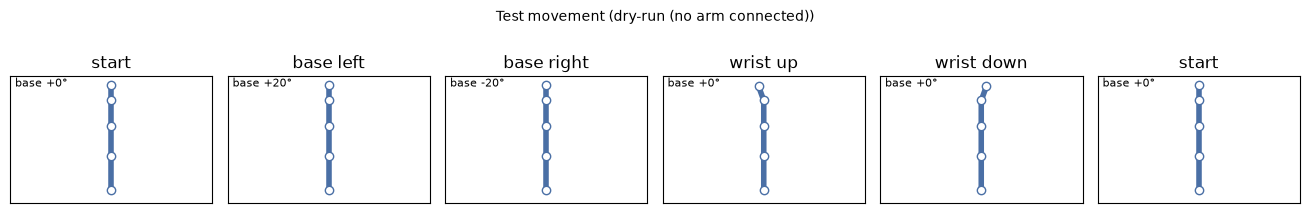

In [9]:
STEP = 20                                              # degrees per nudge: small and safe
HOME = [round(a, 1) for a in (arm.get_angles() or [0.0] * 6)]   # where the arm is right now
print("starting pose:", HOME)


def nudge(joint, delta):
    pose = list(HOME)
    pose[joint] += delta
    return pose


TEST_MOVES = [
    ("start", HOME),
    ("base left", nudge(0, +STEP)),
    ("base right", nudge(0, -STEP)),
    ("wrist up", nudge(3, +STEP)),
    ("wrist down", nudge(3, -STEP)),
    ("start", HOME),
]


def move(arm, angles, speed=SPEED, timeout=15.0):
    """Send a pose and wait until the arm stops (or the timeout passes). Returns the angles read back."""
    arm.send_angles(angles, speed)
    t0 = time.time()
    time.sleep(0.3)
    while time.time() - t0 < timeout:
        try:
            if not arm.is_moving():
                break
        except Exception:
            pass
        time.sleep(0.2)
    return arm.get_angles()


def draw_pose(ax, angles, title=""):
    """Side view of a simplified arm (joints 2, 3, 4 bend in the vertical plane) plus base rotation as text."""
    links = [0.135, 0.12, 0.10, 0.06]                     # approximate link lengths (m)
    x, y, a = [0.0], [0.0], math.pi / 2
    for L, j in zip(links, [0, angles[1], angles[2], angles[3]]):
        a += math.radians(j)
        x.append(x[-1] + L * math.cos(a)); y.append(y[-1] + L * math.sin(a))
    ax.plot(x, y, "-o", lw=4, color="#4a6fa5", mfc="white")
    ax.set(xlim=(-0.4, 0.4), ylim=(-0.05, 0.45), aspect="equal", title=title)
    ax.text(-0.38, 0.41, f"base {angles[0]:+.0f}°", fontsize=8)
    ax.set_xticks([]); ax.set_yticks([])


test_log = []
for label, pose in TEST_MOVES:
    reached = move(arm, pose)
    test_log.append(dict(step=label, target=pose, reached=[round(a, 1) for a in reached]))
display(pd.DataFrame(test_log))

fig, axes = plt.subplots(1, len(TEST_MOVES), figsize=(2.2 * len(TEST_MOVES), 2.4))
for ax, (label, pose) in zip(axes, TEST_MOVES):
    draw_pose(ax, pose, label)
plt.suptitle(f"Test movement ({arm.name})", fontsize=10); plt.tight_layout(); plt.show()

### Objective 5: respond to an OD reading

**The rule.** When the OD rises **above the threshold**, the arm performs one response movement (a "nod").
It then **re-arms only after OD falls back below `threshold − margin`**. This *hysteresis* means noise around
the threshold can't make the arm fire over and over: **one crossing gives exactly one movement**, every time.
That makes the response repeatable, which is the tie-breaker in scoring.

**OD source.** The live reading comes from `latest_od()` in Part A (Pioreactor API). If Part A isn't loaded
or the API is down, a recorded or simulated OD series is used instead, and the notebook says which.

In [10]:
class ThresholdTrigger:
    def __init__(self, threshold, margin):
        self.threshold, self.margin, self.armed = threshold, margin, True

    def update(self, od):
        """Return True exactly once per upward crossing of the threshold."""
        if self.armed and od > self.threshold:
            self.armed = False
            return True
        if not self.armed and od < self.threshold - self.margin:
            self.armed = True
        return False


# Self-check: noisy OD that crosses the threshold twice must fire exactly twice.
rng = np.random.default_rng(0)
test_series = np.concatenate([np.linspace(0.10, 0.30, 40), np.linspace(0.30, 0.10, 40)] * 2) + rng.normal(0, 0.01, 160)
trig = ThresholdTrigger(0.20, 0.03)
fires = [i for i, v in enumerate(test_series) if trig.update(v)]
assert len(fires) == 2, fires
print(f"self-check passed: 2 crossings in noisy data → {len(fires)} triggers (at samples {fires})")

RESPONSE = [("nod down", nudge(3, -STEP)), ("nod up", nudge(3, +STEP)), ("back to start", HOME)]


def respond(arm):
    for _, pose in RESPONSE:
        move(arm, pose)
    return arm.get_angles()

self-check passed: 2 crossings in noisy data → 2 triggers (at samples [19, 100])


live baseline: OD 0.00482 ± 0.00001 over 12 readings
OD source: live Pioreactor OD (experiment bioreactor_robot)
threshold 0.00502, re-arm below 0.0049


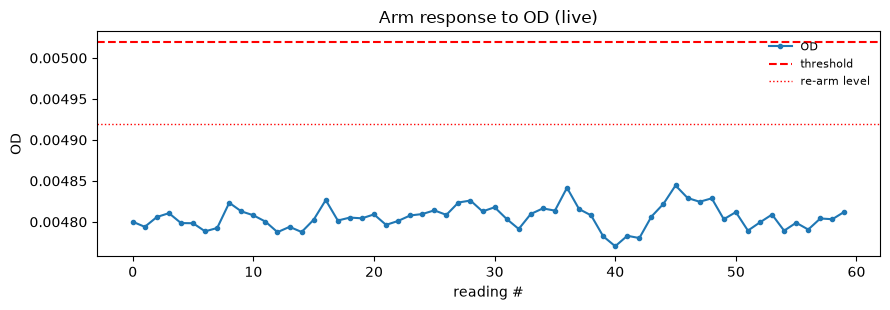

0 responses from 60 readings; log saved to evidence/arm/trigger_log.csv


In [11]:
def simulated_od():
    """Fallback OD: rises past the threshold, falls back, and rises again (two crossings)."""
    for v in np.concatenate([np.linspace(0.10, 0.30, 15), np.linspace(0.30, 0.10, 15), np.linspace(0.10, 0.30, 15)]):
        yield datetime.now(timezone.utc).isoformat(timespec="seconds"), float(v)


live = "latest_od" in globals() and globals().get("EXPERIMENT")
if live:
    first = latest_od(EXPERIMENT)
    live = first is not None
if live:
    SOURCE = f"live Pioreactor OD (experiment {EXPERIMENT})"
    # Threshold from the live signal itself: the last ~12 readings give the current level and its noise.
    # Trigger a little above normal noise (4 standard deviations, at least 0.0002 OD), so noise alone never
    # fires the arm but a real rise in OD does. Re-arm only after OD falls back 2 noise-widths below it.
    # Override for a demo with OD_THRESHOLD / OD_MARGIN environment variables.
    try:
        now_iso = leader_now()
        pts = sorted(get_od_series(EXPERIMENT).get(SERIES_USED, []), key=lambda p: _when(p[0]))
        pts = [p for p in pts if not now_iso or _when(p[0]) <= _when(now_iso)][-12:]
        vals = np.array([p[1] for p in pts]) if len(pts) >= 3 else np.array([first[1]])
    except Exception:
        vals = np.array([first[1]])
    level, noise = float(vals.mean()), float(vals.std())
    THRESHOLD = float(os.environ.get("OD_THRESHOLD", round(level + max(4 * noise, 0.0002), 5)))
    MARGIN = float(os.environ.get("OD_MARGIN", round(max(2 * noise, 0.0001), 5)))
    print(f"live baseline: OD {level:.5f} ± {noise:.5f} over {len(vals)} readings")
    POLLS, EVERY = 60, 5.0                     # 5 minutes of polling every 5 s
    def readings():
        for _ in range(POLLS):
            r = latest_od(EXPERIMENT)
            if r:
                yield r
            time.sleep(EVERY)
else:
    SOURCE = "simulated OD (Part A not connected: live API unavailable)"
    THRESHOLD, MARGIN = 0.20, 0.03
    readings = simulated_od
print(f"OD source: {SOURCE}\nthreshold {THRESHOLD}, re-arm below {THRESHOLD - MARGIN:.4f}")

trigger = ThresholdTrigger(THRESHOLD, MARGIN)
log = []
for ts, od in readings():
    fired = trigger.update(od)
    pose = respond(arm) if fired else None
    log.append(dict(time=ts, od=od, threshold=THRESHOLD, event="ARM MOVED" if fired else "",
                    pose=[round(a, 1) for a in pose] if pose else ""))
    if fired:
        print(f"{ts}  OD {od:.4f} > {THRESHOLD}  →  arm responded")
log = pd.DataFrame(log)
log.to_csv(EVIDENCE / "trigger_log.csv", index=False)

fig, ax = plt.subplots(figsize=(9, 3.2))
ax.plot(range(len(log)), log.od, "-o", ms=3, label="OD")
ax.axhline(THRESHOLD, color="r", ls="--", label="threshold")
ax.axhline(THRESHOLD - MARGIN, color="r", ls=":", lw=1, label="re-arm level")
for i in log.index[log.event != ""]:
    ax.axvline(i, color="green", alpha=0.4); ax.text(i, ax.get_ylim()[1], " arm", color="green", fontsize=8, va="top")
ax.set(xlabel="reading #", ylabel="OD", title=f"Arm response to OD ({SOURCE})"); ax.legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()
print(f"{(log.event != '').sum()} responses from {len(log)} readings; log saved to {EVIDENCE / 'trigger_log.csv'}")